# <span style="color:green"> Laboratorio di simulazione Numerica </span>
## <span style="color:blue">  Tommaso Cardano Chiezzi</span>

# Esercizio 04 — Molecular Dynamics

## 04.1 — Distribuzione delle velocità di Maxwell-Boltzmann

In questo esercizio viene introdotto e testato il simulatore di **Molecular Dynamics** utilizzato nel laboratorio.

Il sistema considerato è costituito da particelle classiche interagenti tramite il potenziale di Lennard-Jones. La dinamica viene simulata nell'ensemble microcanonico \(NVE\), integrando numericamente le equazioni del moto mediante l'algoritmo di Verlet.

Come primo controllo del corretto funzionamento del simulatore vengono analizzati:

- l'andamento dell'energia cinetica, potenziale e totale;
- la conservazione dell'energia totale;
- l'andamento della temperatura;
- la distribuzione del modulo delle velocità delle particelle.

Quest'ultima viene confrontata con la distribuzione teorica di Maxwell-Boltzmann alla temperatura effettivamente misurata durante la simulazione.

## Simulatore di Molecular Dynamics

Il simulatore descrive un sistema tridimensionale di $N$ particelle classiche che interagiscono tramite il potenziale di Lennard-Jones

$$
V(r)
=
4\epsilon
\left[
\left(\frac{\sigma}{r}\right)^{12}
-
\left(\frac{\sigma}{r}\right)^6
\right].
$$

Il termine proporzionale a $r^{-12}$ descrive la forte repulsione a breve distanza, mentre il termine proporzionale a $r^{-6}$ rappresenta l'interazione attrattiva.

Le simulazioni vengono effettuate utilizzando le **unità ridotte di Lennard-Jones**, scegliendo $\sigma$, $\epsilon$ e $m$ come unità fondamentali di lunghezza, energia e massa:

$$
r^*=\frac{r}{\sigma},
\qquad
T^*=\frac{k_BT}{\epsilon},
\qquad
E^*=\frac{E}{\epsilon}.
$$

L'unità naturale di tempo è

$$
\tau
=
\sigma\sqrt{\frac{m}{\epsilon}},
$$

mentre quella di velocità è

$$
\sqrt{\frac{\epsilon}{m}},
$$

per cui

$$
v^*
=
v\sqrt{\frac{m}{\epsilon}}.
$$

In queste unità il potenziale diventa

$$
V^*(r^*)
=
4
\left[
\frac{1}{(r^*)^{12}}
-
\frac{1}{(r^*)^6}
\right].
$$

La simulazione viene inizializzata a partire dalle posizioni delle particelle contenute in una configurazione iniziale. Per un fluido è conveniente partire da una disposizione ordinata, ad esempio un reticolo cristallino, evitando configurazioni completamente casuali che potrebbero produrre sovrapposizioni tra particelle e quindi forze repulsive estremamente elevate.

Se viene iniziata una nuova simulazione, le componenti delle velocità vengono estratte da distribuzioni gaussiane, viene eliminata la velocità del centro di massa e le velocità vengono successivamente riscalate in modo consistente con la temperatura iniziale.

## Condizioni periodiche, cutoff e integrazione della dinamica

Poiché è possibile simulare solamente un numero finito di particelle, vengono utilizzate **condizioni periodiche al contorno** (Periodic Boundary Conditions, PBC).

La scatola di simulazione viene immaginata replicata periodicamente nello spazio. Quando una particella attraversa una faccia della scatola, una sua immagine entra dalla faccia opposta.

Le distanze tra le particelle vengono calcolate utilizzando la **minimum-image convention**, considerando per ogni coppia la separazione periodica minima.

Poiché il potenziale di Lennard-Jones è a corto raggio, le interazioni vengono inoltre trascurate oltre un raggio di cutoff $r_c$:

$$
V(r) \simeq 0
\qquad
\text{per}
\qquad
r>r_c.
$$

Per essere compatibile con la minimum-image convention deve essere soddisfatta la condizione

$$
r_c \leq \frac{L}{2},
$$

dove $L$ è il lato della scatola.

Nella simulazione di esempio che verrà considerata in questa prima parte si ha:

$$
N=108,
\qquad
\rho^*=0.8,
\qquad
L\simeq5.13,
\qquad
r_c=2.5,
$$

e quindi

$$
r_c < \frac{L}{2}\simeq2.565.
$$

La dinamica viene simulata nell'ensemble microcanonico $NVE$, nel quale rimangono costanti il numero di particelle, il volume e l'energia totale.

Le equazioni di Newton vengono integrate mediante l'algoritmo di Verlet:

$$
\mathbf r(t+\Delta t)
\simeq
2\mathbf r(t)
-
\mathbf r(t-\Delta t)
+
\mathbf a(t)\Delta t^2.
$$

La velocità viene ricostruita dalla traiettoria attraverso

$$
\mathbf v(t)
\simeq
\frac{
\mathbf r(t+\Delta t)
-
\mathbf r(t-\Delta t)
}{
2\Delta t
}.
$$

L'algoritmo di Verlet è particolarmente adatto alla Molecular Dynamics grazie alla reversibilità temporale e alle buone proprietà di conservazione dell'energia.

## Osservabili, equilibrazione e analisi statistica

Durante l'evoluzione dinamica vengono misurate alcune grandezze termodinamiche del sistema:

$$
\frac{U}{N},
\qquad
\frac{K}{N},
\qquad
\frac{E}{N},
\qquad
T,
$$

con

$$
E = K + U.
$$

Poiché la simulazione viene effettuata nell'ensemble $NVE$, la temperatura non viene mantenuta costante mediante un termostato, ma viene ricavata dall'energia cinetica attraverso il principio di equipartizione:

$$
2K = 3Nk_B T.
$$

In unità ridotte:

$$
\boxed{
T^*
=
\frac{2}{3}\frac{K^*}{N}
}.
$$

La temperatura misurata lungo la traiettoria rappresenta quindi la temperatura effettiva del sistema simulato.

## Temperatura ed equilibrazione

Poiché la simulazione viene effettuata nell'ensemble microcanonico $NVE$, la temperatura non viene mantenuta costante mediante un termostato, ma viene ricavata dall'energia cinetica attraverso il principio di equipartizione:

$$
2K = 3Nk_B T.
$$

In unità ridotte:

$$
\boxed{
T^*
=
\frac{2}{3}\frac{K^*}{N}
}.
$$

La temperatura rappresenta quindi una grandezza misurata durante l'evoluzione dinamica del sistema.

All'inizio della simulazione la configurazione assegnata non rappresenta necessariamente uno stato di equilibrio. Durante i primi passi il sistema attraversa quindi un **transiente iniziale**, durante il quale la temperatura può variare in modo sistematico mentre energia cinetica e potenziale si redistribuiscono.

Il sistema può essere considerato equilibrato quando la temperatura non mostra più una deriva sistematica, ma presenta solamente fluttuazioni attorno a un valore medio stabile:

$$
T^*(t)
\simeq
\langle T^* \rangle
+
\text{fluttuazioni}.
$$

Il valore della temperatura di equilibrio non deve quindi coincidere necessariamente con il valore utilizzato per inizializzare la simulazione.

Una volta raggiunto l'equilibrio, la media della temperatura misurata lungo la traiettoria può essere utilizzata per caratterizzare lo stato termodinamico effettivamente campionato.

Per questo motivo, nel confronto con la distribuzione teorica di Maxwell-Boltzmann viene utilizzata la **temperatura media misurata durante la simulazione**, anziché assumere direttamente il valore iniziale specificato nell'input.
### Data blocking

La simulazione viene suddivisa in $N_{\mathrm{blocks}}$ blocchi, ciascuno formato da $N_{\mathrm{steps}}$ passi.

Per ogni blocco viene calcolata una media $A_i$ e da queste vengono costruite la media progressiva

$$
\langle A\rangle_n
=
\frac{1}{n}
\sum_{i=1}^{n} A_i
$$

e la relativa incertezza statistica.

Il data blocking permette di ridurre l'effetto delle correlazioni tra configurazioni successive della traiettoria e di ottenere una stima dell'incertezza statistica sulle osservabili.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Cartella contenente gli output del simulatore
output_dir = Path("Esercizio_04.1/NSL_SIMULATOR/OUTPUT")

# Lettura dei risultati
temperature = np.loadtxt(output_dir / "temperature.dat")
kinetic_energy = np.loadtxt(output_dir / "kinetic_energy.dat")
potential_energy = np.loadtxt(output_dir / "potential_energy.dat")
total_energy = np.loadtxt(output_dir / "total_energy.dat")
pofv = np.loadtxt(output_dir / "pofv.dat")

print("Numero di blocchi:", len(temperature))

Numero di blocchi: 1000


## Controllo preliminare della dinamica

Prima di analizzare la distribuzione delle velocità è opportuno verificare che la simulazione di Molecular Dynamics presenti un comportamento fisicamente corretto.

Poiché la simulazione viene effettuata nell'ensemble $NVE$, l'energia cinetica e quella potenziale possono variare nel tempo, scambiandosi continuamente energia, mentre l'energia totale deve rimanere approssimativamente costante:

$$
E = K + U \simeq \text{costante}.
$$

Una deriva sistematica dell'energia totale indicherebbe un'integrazione numerica non sufficientemente accurata, ad esempio a causa di un passo temporale troppo grande.

La conservazione dell'energia costituisce quindi uno dei principali controlli di affidabilità della simulazione.

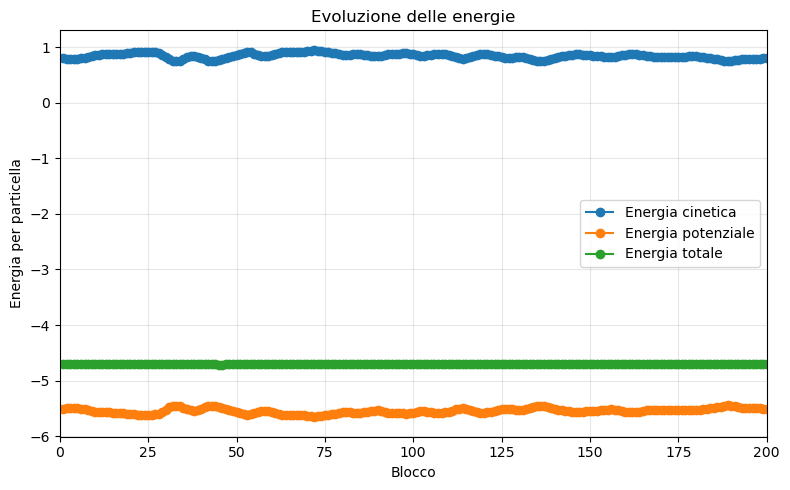

In [15]:
blocks = total_energy[:, 0]

plt.figure(figsize=(8, 5))

plt.plot(
    blocks,
    kinetic_energy[:, 1],
    "o-",
    label="Energia cinetica"
)

plt.plot(
    blocks,
    potential_energy[:, 1],
    "o-",
    label="Energia potenziale"
)

plt.plot(
    blocks,
    total_energy[:, 1],
    "o-",
    label="Energia totale"
)

plt.xlabel("Blocco")
plt.xlim(0, 200)
plt.ylabel(r"Energia per particella")
plt.title("Evoluzione delle energie")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

L'energia cinetica e l'energia potenziale presentano oscillazioni dovute al continuo scambio di energia durante l'evoluzione dinamica.

La loro somma rimane invece quasi costante, come richiesto da una simulazione nell'ensemble microcanonico $NVE$.

Per osservare più chiaramente la conservazione dell'energia totale viene riportata separatamente la sua media progressiva con la relativa incertezza statistica.

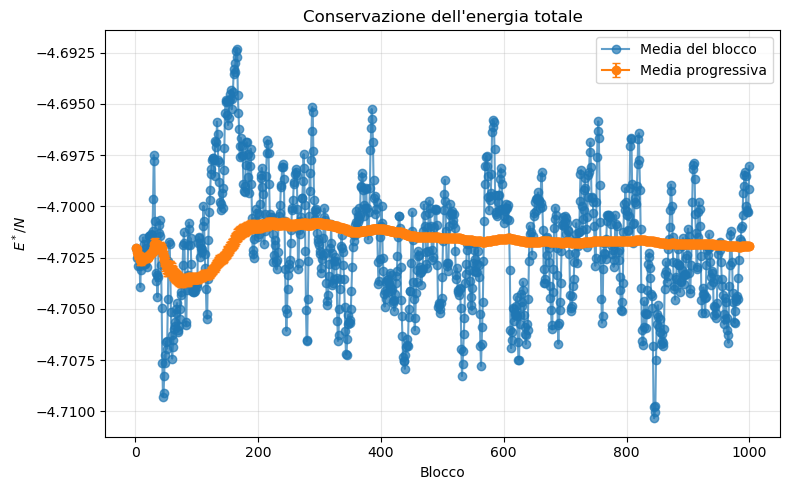

Energia totale finale = -4.70192 ± 0.00009


In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    blocks,
    total_energy[:, 1],
    "o-",
    alpha=0.7,
    label="Media del blocco"
)

plt.errorbar(
    blocks,
    total_energy[:, 2],
    yerr=total_energy[:, 3],
    fmt="o-",
    capsize=3,
    label="Media progressiva"
)

plt.xlabel("Blocco")
plt.ylabel(r"$E^*/N$")
plt.title("Conservazione dell'energia totale")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

print(
    f"Energia totale finale = "
    f"{total_energy[-1,2]:.5f} ± {total_energy[-1,3]:.5f}"
)

## Temperatura del sistema

Nella simulazione $NVE$ la temperatura non è una quantità mantenuta artificialmente costante durante la dinamica.

Essa viene ricavata dall'energia cinetica tramite

$$
T^*
=
\frac{2}{3}
\frac{K^*}{N}.
$$

Di conseguenza, per caratterizzare lo stato termodinamico effettivamente campionato dalla simulazione deve essere utilizzata la **temperatura misurata lungo la traiettoria**.

Nel confronto con la distribuzione teorica di Maxwell-Boltzmann verrà quindi utilizzato il valore finale della media progressiva della temperatura.

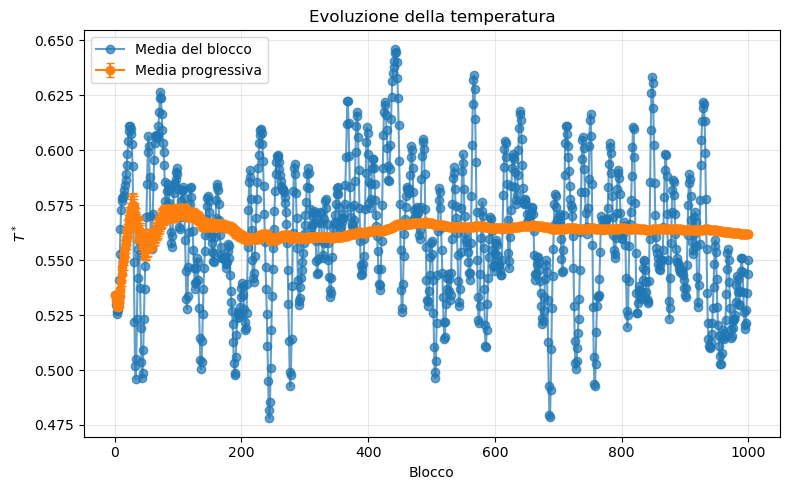

Temperatura misurata: T* = 0.56171 ± 0.00095


In [12]:
blocks = temperature[:, 0]

T_block = temperature[:, 1]
T_prog = temperature[:, 2]
T_err = temperature[:, 3]

plt.figure(figsize=(8, 5))

plt.plot(
    blocks,
    T_block,
    "o-",
    alpha=0.7,
    label="Media del blocco"
)

plt.errorbar(
    blocks,
    T_prog,
    yerr=T_err,
    fmt="o-",
    capsize=3,
    label="Media progressiva"
)

plt.xlabel("Blocco")
plt.ylabel(r"$T^*$")
plt.title("Evoluzione della temperatura")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

T_sim = T_prog[-1]
T_sim_err = T_err[-1]

print(
    f"Temperatura misurata: "
    f"T* = {T_sim:.5f} ± {T_sim_err:.5f}"
)

Il valore finale della temperatura media progressiva risulta circa

$$
T^*
\simeq
0.562.
$$

Questo valore rappresenta la temperatura effettiva dello stato campionato dalla traiettoria di Molecular Dynamics e viene quindi utilizzato per costruire la distribuzione teorica di Maxwell-Boltzmann.

## Distribuzione delle velocità di Maxwell-Boltzmann

Per un sistema classico all'equilibrio termico, le singole componenti della velocità seguono distribuzioni gaussiane.

Il modulo della velocità,

$$
v
=
\sqrt{
v_x^2
+
v_y^2
+
v_z^2
},
$$

segue invece la distribuzione di Maxwell-Boltzmann:

$$
p(v,T)
=
4\pi v^2
\left(
\frac{m}{2\pi k_B T}
\right)^{3/2}
\exp
\left(
-\frac{mv^2}{2k_B T}
\right).
$$

Passando alle unità ridotte di Lennard-Jones,

$$
v^*
=
v
\sqrt{\frac{m}{\epsilon}},
$$

e

$$
T^*
=
\frac{k_B T}{\epsilon},
$$

si ottiene

$$
\boxed{
p(v^*,T^*)
=
\frac{
4\pi(v^*)^2
}{
(2\pi T^*)^{3/2}
}
\exp
\left[
-\frac{(v^*)^2}{2T^*}
\right]
}.
$$

La distribuzione soddisfa la condizione di normalizzazione

$$
\int_0^\infty
p(v^*,T^*)
\,dv^*
=
1.
$$

L'obiettivo dell'esercizio consiste nel verificare che la distribuzione delle velocità prodotta dalla simulazione di Molecular Dynamics sia compatibile con questa distribuzione teorica.

In [13]:
# Numero dell'ultimo blocco
last_block = int(np.max(pofv[:, 0]))

# Selezione dei dati relativi all'ultimo blocco
pofv_final = pofv[pofv[:, 0] == last_block]

v = pofv_final[:, 1]
p_sim = pofv_final[:, 3]
p_err = pofv_final[:, 4]

# Ampiezza dei bin
dv = v[1] - v[0]

# Controllo della normalizzazione
normalization = np.sum(p_sim * dv)

print(f"Numero di bin = {len(v)}")
print(f"Δv = {dv:.6f}")
print(f"Integrale numerico di p(v*) = {normalization:.6f}")

Numero di bin = 30
Δv = 0.139841
Integrale numerico di p(v*) = 1.000002


La corretta normalizzazione dell'istogramma può essere verificata numericamente attraverso

$$
\int p(v^*)\,dv^*
\approx
\sum_i
p_i\Delta v.
$$

Un valore prossimo a $1$ indica che l'istogramma numerico rappresenta correttamente una densità di probabilità.

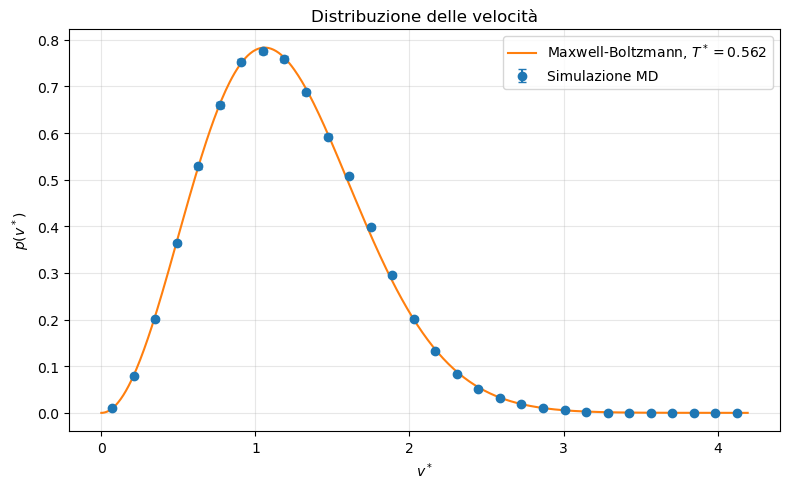

In [14]:
def maxwell_boltzmann(v, T):
    return (
        4.0 * np.pi * v**2
        / (2.0 * np.pi * T)**1.5
        * np.exp(-v**2 / (2.0 * T))
    )


# Griglia continua per la curva teorica
v_theory = np.linspace(
    0.0,
    v.max() + dv / 2,
    500
)

# Maxwell-Boltzmann alla temperatura misurata
p_theory = maxwell_boltzmann(
    v_theory,
    T_sim
)


plt.figure(figsize=(8, 5))

plt.errorbar(
    v,
    p_sim,
    yerr=p_err,
    fmt="o",
    capsize=3,
    label="Simulazione MD"
)

plt.plot(
    v_theory,
    p_theory,
    label=rf"Maxwell-Boltzmann, $T^*={T_sim:.3f}$"
)

plt.xlabel(r"$v^*$")
plt.ylabel(r"$p(v^*)$")
plt.title("Distribuzione delle velocità")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

## Risultati

L'energia totale rimane stabile durante la simulazione, indicando che l'integrazione delle equazioni del moto mediante l'algoritmo di Verlet conserva correttamente l'energia del sistema entro la precisione numerica.

La temperatura viene ricavata dall'energia cinetica e raggiunge un valore medio di circa

$$
T^*
\simeq
0.562.
$$

La distribuzione numerica del modulo delle velocità risulta correttamente normalizzata:

$$
\int
p(v^*)
\,dv^*
\simeq
1.
$$

Il confronto con la distribuzione teorica di Maxwell-Boltzmann, calcolata utilizzando la temperatura effettivamente misurata durante la simulazione, mostra un buon accordo.

Il test permette quindi di verificare il corretto funzionamento del simulatore di Molecular Dynamics e dell'implementazione della misura della distribuzione delle velocità $p(v^*)$.

Nelle sezioni successive il simulatore verrà utilizzato per lo studio di sistemi Lennard-Jones in specifiche condizioni termodinamiche.

# Esercizio 04.2 — Evoluzione di un sistema di particelle di Argon

In questa parte viene studiata mediante Molecular Dynamics l'evoluzione di un sistema Lennard-Jones di particelle di Argon inizializzato in una configurazione fortemente fuori equilibrio.

La simulazione viene effettuata nella fase gassosa utilizzando i parametri

$$
\rho^*=0.05,
\qquad
T^*=2.0,
\qquad
r_c=5.0.
$$

Vengono utilizzate

$$
N=256
$$

particelle, disposte inizialmente su un reticolo FCC formato da

$$
4\times4\times4
$$

celle convenzionali, con $4$ particelle per cella.

Il reticolo viene confinato in una regione che occupa metà della scatola di simulazione lungo ciascuna direzione. Il volume inizialmente occupato è quindi solamente

$$
\left(\frac{1}{2}\right)^3
=
\frac{1}{8}
$$

del volume totale disponibile.

Questa configurazione iniziale presenta quindi un forte ordine spaziale e rappresenta uno stato a bassa entropia.

Anche la distribuzione iniziale delle velocità viene scelta in modo fortemente non equilibrato. Tutte le particelle possiedono inizialmente lo stesso modulo della velocità,

$$
v_T^*=\sqrt{3T^*},
$$

che per $T^*=2$ vale

$$
v_T^*=\sqrt{6}\simeq2.45.
$$

La distribuzione iniziale del modulo delle velocità è quindi idealmente

$$
p_0(v^*)
=
\delta(v^*-v_T^*).
$$

Le direzioni vengono scelte tra le sei direzioni cartesiane

$$
\pm\hat{x},
\qquad
\pm\hat{y},
\qquad
\pm\hat{z}.
$$

Le velocità vengono assegnate in coppie opposte,

$$
\mathbf v_j=-\mathbf v_i,
$$

in modo da garantire esattamente

$$
\sum_{i=1}^{N}\mathbf v_i=0.
$$

In particolare vengono utilizzate $43$ coppie lungo l'asse $x$, $43$ lungo l'asse $y$ e $42$ lungo l'asse $z$. Le direzioni vengono poi distribuite casualmente tra le particelle, evitando una correlazione artificiale tra posizione nel reticolo e direzione della velocità.

L'obiettivo è osservare come il sistema perda progressivamente memoria di questa configurazione iniziale molto ordinata e si avvicini a uno stato di equilibrio, sia nello spazio delle posizioni sia nello spazio delle velocità.

In particolare verranno analizzati:

- l'evoluzione della temperatura e delle energie;
- l'espansione delle particelle all'interno della scatola;
- il rilassamento della distribuzione delle velocità;
- il confronto dello stato finale con la distribuzione di Maxwell-Boltzmann;
- l'evoluzione qualitativa verso configurazioni a maggiore entropia.

## Parametri numerici e data blocking

Le equazioni del moto vengono integrate utilizzando un passo temporale ridotto

$$
\Delta t^*=0.001.
$$

corrispondente ad un intervallo temporale di $2.15 fs$.

La simulazione viene suddivisa in

$$
N_{\mathrm{blocks}}=1000
$$

blocchi, ciascuno costituito da

$$
N_{\mathrm{steps}}=100
$$

passi di Molecular Dynamics.

Ogni blocco rappresenta quindi un intervallo temporale

$$
\Delta t_{\mathrm{block}}^*
=
N_{\mathrm{steps}}\Delta t^*
=
100\cdot0.001
=
0.1.
$$

Il numero totale di passi è

$$
N_{\mathrm{tot}}
=
1000\cdot100
=
10^5,
$$

corrispondente a un tempo totale

$$
t_{\max}^*
=
N_{\mathrm{tot}}\Delta t^*
=
100.
$$

Di conseguenza il blocco $n$ corrisponde approssimativamente al tempo

$$
t_n^*=0.1\,n.
$$

La scelta di blocchi relativamente brevi permette di seguire con buona risoluzione temporale il rapido rilassamento iniziale, mentre la lunga durata complessiva della simulazione permette di ottenere una regione sufficientemente estesa in condizioni di equilibrio.

Per la distribuzione del modulo delle velocità l'intervallo considerato viene suddiviso in $60$ bin. Per ciascun bin vengono accumulate le misure all'interno dei blocchi, permettendo di studiare sia l'evoluzione temporale di $p(v^*)$ sia la sua distribuzione media nella regione di equilibrio.

## Temperatura effettiva ed equilibrazione

La simulazione viene effettuata nell'ensemble microcanonico $NVE$, nel quale il numero di particelle, il volume e l'energia totale rimangono costanti.

L'energia totale è

$$
E=K+U,
$$

e deve rimanere approssimativamente conservata durante tutta l'evoluzione.

La temperatura non è invece una costante del moto, ma viene ricavata dall'energia cinetica attraverso

$$
T^*
=
\frac{2}{3}\frac{K^*}{N}.
$$

La particolare scelta iniziale

$$
|\mathbf v_i^*|=\sqrt{6}
$$

per tutte le particelle garantisce inizialmente

$$
\frac{1}{N}\sum_{i=1}^{N}v_i^{*2}=6,
$$

e quindi

$$
T^*(0)=2.
$$

Questo valore rappresenta però solamente la temperatura cinetica associata alla configurazione iniziale.

Il sistema parte infatti da uno stato fortemente fuori equilibrio: le particelle sono concentrate in una piccola regione dello spazio, le posizioni sono ordinate secondo un reticolo FCC e tutti i moduli delle velocità sono inizialmente uguali.

Durante il rilassamento iniziale energia cinetica ed energia potenziale vengono redistribuite, pur mantenendo approssimativamente costante

$$
E=K+U.
$$

Di conseguenza la temperatura può cambiare sensibilmente rispetto al valore iniziale $T^*=2$.

L'equilibrazione viene individuata osservando l'andamento di $T^*$ nel tempo. Una volta terminata la deriva iniziale, la temperatura oscilla attorno a un valore medio approssimativamente stabile.

La temperatura rilevante per descrivere lo stato finale è quindi la temperatura effettiva di equilibrio

$$
\boxed{T_{\mathrm{eff}}^*},
$$

ottenuta mediando la temperatura solamente nella regione equilibrata della traiettoria.

Il confronto finale della distribuzione delle velocità viene quindi effettuato con la distribuzione di Maxwell-Boltzmann

$$
p(v^*,T_{\mathrm{eff}}^*)
=
\frac{4\pi(v^*)^2}
{(2\pi T_{\mathrm{eff}}^*)^{3/2}}
\exp
\left[
-\frac{(v^*)^2}{2T_{\mathrm{eff}}^*}
\right].
$$

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Cartella contenente i risultati della simulazione
output_dir = Path("Esercizio_04.2/NSL_SIMULATOR/OUTPUT")

# Lettura dei file di output
temperature = np.loadtxt(output_dir / "temperature.dat")
kinetic_energy = np.loadtxt(output_dir / "kinetic_energy.dat")
potential_energy = np.loadtxt(output_dir / "potential_energy.dat")
total_energy = np.loadtxt(output_dir / "total_energy.dat")
pofv = np.loadtxt(output_dir / "pofv.dat")

# Parametri temporali della simulazione
delta_t = 0.001
nsteps_per_block = 100

# Tempo associato a ciascun blocco
blocks = temperature[:, 0]
time = blocks * nsteps_per_block * delta_t

print("Numero di blocchi:", len(blocks))
print("Tempo finale t* =", time[-1])

Numero di blocchi: 1000
Tempo finale t* = 100.0


## Evoluzione della temperatura

La temperatura viene utilizzata come prima osservabile per individuare il raggiungimento dell'equilibrio.

Poiché la simulazione è effettuata nell'ensemble $NVE$, la temperatura può variare durante il transiente iniziale mentre energia cinetica e potenziale si redistribuiscono.

Il sistema può essere considerato equilibrato quando la temperatura non presenta più una deriva sistematica, ma oscilla attorno a un valore medio approssimativamente costante.

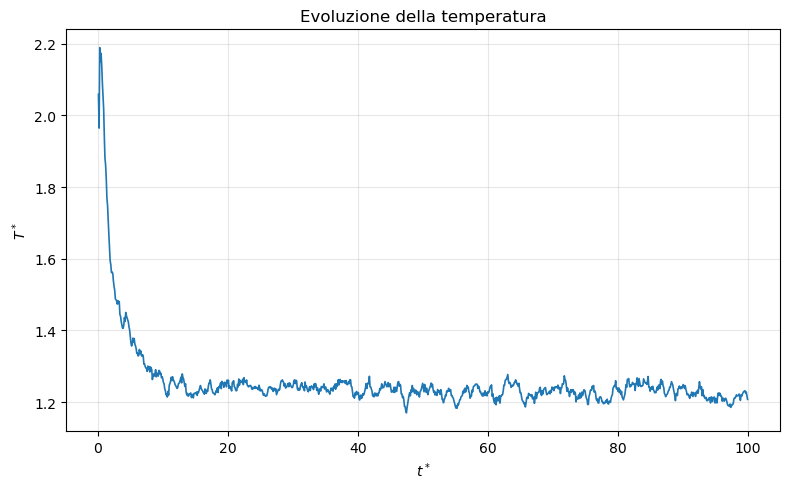

In [64]:
# Temperatura del singolo blocco
T_block = temperature[:, 1]

plt.figure(figsize=(8, 5))

plt.plot(
    time,
    T_block,
    linewidth=1.2
)

plt.xlabel(r"$t^*$")
plt.ylabel(r"$T^*$")
plt.title("Evoluzione della temperatura")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Regione di equilibrio

L'andamento della temperatura mostra un rapido rilassamento iniziale a partire dalla condizione $T^*=2$.

Nei primi tempi la temperatura diminuisce sensibilmente, indicando una redistribuzione dell'energia tra componente cinetica e potenziale. Successivamente le oscillazioni diventano più stazionarie.

Per escludere in modo conservativo il transiente iniziale viene scelta come regione di equilibrio

$$
t^* \geq t_{\mathrm{eq}}^* = 40.
$$

La temperatura effettiva del sistema viene quindi stimata utilizzando solamente i blocchi appartenenti a questa regione.

In [65]:
# Tempo scelto per l'inizio della regione di equilibrio
t_eq = 40.0

# Selezione dei blocchi equilibrati
mask_eq = time >= t_eq

T_eq = T_block[mask_eq]

# Temperatura media nella regione equilibrata
T_eff = np.mean(T_eq)

# Incertezza statistica sulla media
T_eff_err = np.std(T_eq, ddof=1) / np.sqrt(len(T_eq))

print(f"Numero di blocchi equilibrati: {len(T_eq)}")
print(f"T_eff* = {T_eff:.5f} ± {T_eff_err:.5f}")

Numero di blocchi equilibrati: 601
T_eff* = 1.22752 ± 0.00074


La temperatura effettiva viene ottenuta mediando esclusivamente la parte equilibrata della traiettoria.

Questa quantità è differente dalla temperatura iniziale $T^*=2$, poiché nella simulazione microcanonica non viene mantenuta costante la temperatura, ma l'energia totale.

Durante il rilassamento iniziale si verifica quindi uno scambio tra energia cinetica e potenziale, fino al raggiungimento di uno stato caratterizzato da fluttuazioni della temperatura attorno a un valore medio stabile.

## Evoluzione delle energie

Per verificare il corretto comportamento della dinamica viene analizzato l'andamento dell'energia cinetica, potenziale e totale.

Nell'ensemble microcanonico $NVE$ l'energia cinetica e quella potenziale non sono separatamente conservate:

$$
K^*(t) \neq \text{costante},
\qquad
U^*(t) \neq \text{costante},
$$

mentre deve risultare

$$
E^*(t)
=
K^*(t)+U^*(t)
\simeq
\text{costante}.
$$

La conservazione dell'energia totale rappresenta quindi un controllo fondamentale della stabilità numerica della simulazione.

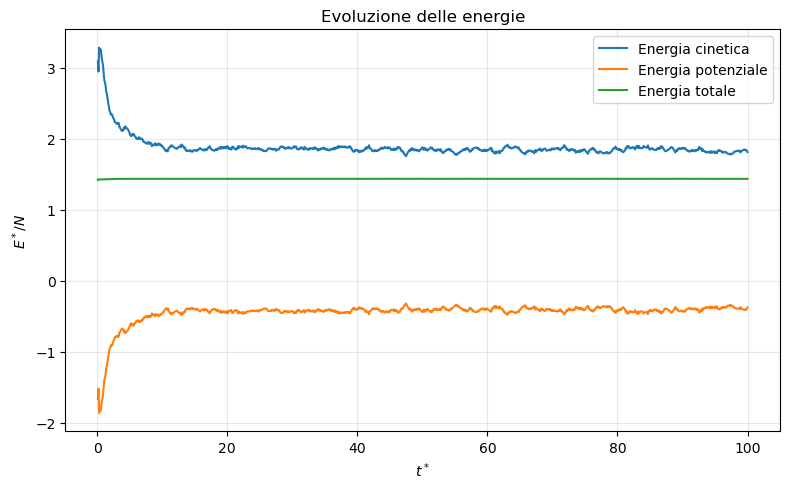

In [66]:
K_block = kinetic_energy[:, 1]
U_block = potential_energy[:, 1]
E_block = total_energy[:, 1]

plt.figure(figsize=(8, 5))

plt.plot(time, K_block, label="Energia cinetica")
plt.plot(time, U_block, label="Energia potenziale")
plt.plot(time, E_block, label="Energia totale")

plt.xlabel(r"$t^*$")
plt.ylabel(r"$E^*/N$")
plt.title("Evoluzione delle energie")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

Durante il transiente iniziale l'energia cinetica diminuisce mentre quella potenziale varia in direzione opposta.

Questo comportamento riflette la redistribuzione dell'energia durante l'espansione e il rilassamento della configurazione iniziale.

La somma delle due componenti deve invece rimanere approssimativamente costante durante tutta la simulazione.

## Evoluzione della distribuzione delle velocità

La condizione iniziale è stata costruita imponendo lo stesso modulo della velocità a tutte le particelle:

$$
v_i^*=v_T^*=\sqrt{3T^*}.
$$

Con $T^*=2$ si ottiene

$$
v_T^*=\sqrt{6}\simeq2.45.
$$

La distribuzione iniziale è quindi idealmente

$$
p_0(v^*)
=
\delta(v^*-v_T^*).
$$

Durante l'evoluzione dinamica le collisioni e le interazioni tra le particelle redistribuiscono progressivamente energia e quantità di moto.

Ci si aspetta quindi che il picco iniziale si allarghi fino ad assumere la forma della distribuzione di Maxwell-Boltzmann corrispondente alla temperatura effettiva di equilibrio.

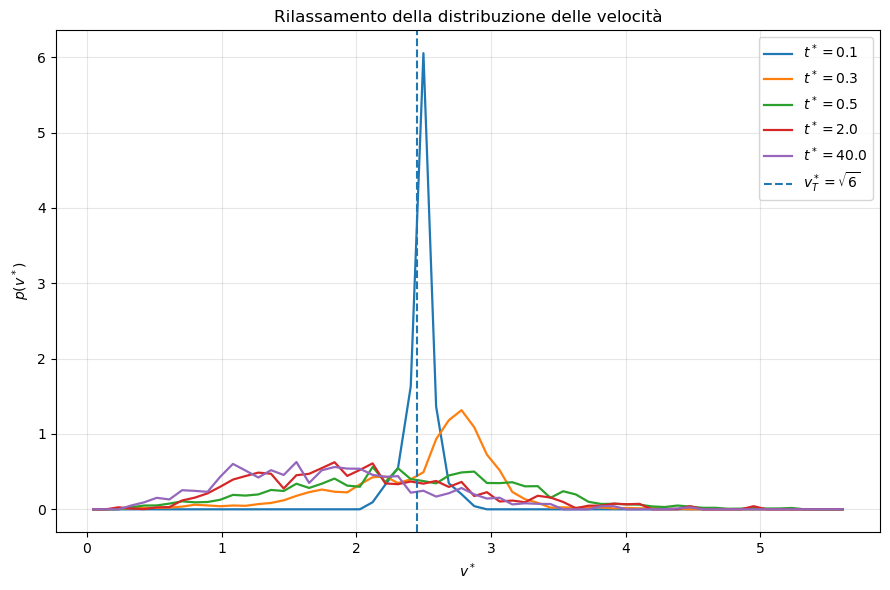

In [67]:
p_blocks = pofv[:, 0]
v_values = pofv[:, 1]
p_actual = pofv[:, 2]
p_progressive = pofv[:, 3]
p_error = pofv[:, 4]

selected_blocks = [1,  3,  5,  20, 400]

plt.figure(figsize=(9, 6))

for blk in selected_blocks:

    mask = p_blocks == blk

    v_blk = v_values[mask]
    p_blk = p_actual[mask]

    t_blk = blk * nsteps_per_block * delta_t

    plt.plot(
        v_blk,
        p_blk,
        linewidth=1.6,
        label=rf"$t^*={t_blk:.1f}$"
    )

plt.axvline(
    np.sqrt(6),
    linestyle="--",
    label=r"$v_T^*=\sqrt{6}$"
)

plt.xlabel(r"$v^*$")
plt.ylabel(r"$p(v^*)$")
plt.title("Rilassamento della distribuzione delle velocità")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

### Rilassamento della distribuzione delle velocità

L'evoluzione della distribuzione delle velocità mostra chiaramente la perdita progressiva della struttura iniziale.

Al primo tempo osservato, $t^*=0.1$, la distribuzione presenta ancora un picco molto stretto in prossimità del valore iniziale

$$
v_T^*=\sqrt{6}.
$$

Questo comportamento riflette la condizione iniziale

$$
p_0(v^*)=\delta(v^*-v_T^*),
$$

nella quale tutte le particelle possiedono lo stesso modulo della velocità.

Già nei tempi successivi il picco si allarga rapidamente: le interazioni tra le particelle redistribuiscono energia e quantità di moto, generando velocità di modulo differente.

La distribuzione perde quindi progressivamente memoria della condizione iniziale e assume una forma più larga e asimmetrica, caratteristica dello stato di equilibrio.



In [68]:
# Regione considerata all'equilibrio
t_eq = 40.0

# Primo blocco appartenente alla regione equilibrata
block_eq = int(np.ceil(
    t_eq / (nsteps_per_block * delta_t)
))

# Valori distinti della velocità
v_eq = np.unique(v_values)

# Distribuzioni dei singoli blocchi equilibrati
equilibrium_distributions = []

for blk in np.unique(p_blocks):

    if blk >= block_eq:

        mask = p_blocks == blk

        equilibrium_distributions.append(
            p_actual[mask]
        )

equilibrium_distributions = np.array(
    equilibrium_distributions
)

# Media temporale della distribuzione
p_eq = np.mean(
    equilibrium_distributions,
    axis=0
)

# Errore sulla media
p_eq_err = np.std(
    equilibrium_distributions,
    axis=0,
    ddof=1
) / np.sqrt(len(equilibrium_distributions))

print(
    "Numero di blocchi utilizzati:",
    len(equilibrium_distributions)
)

Numero di blocchi utilizzati: 601


## Distribuzione delle velocità all'equilibrio

Una singola distribuzione misurata a un determinato istante presenta inevitabilmente fluttuazioni statistiche dovute al numero finito di particelle.

Per ottenere una stima più accurata della distribuzione di equilibrio vengono quindi considerate solamente le configurazioni successive al tempo di equilibrazione

$$
t^*_{\mathrm{eq}}=40.
$$

Le distribuzioni misurate nei blocchi appartenenti alla regione equilibrata vengono mediate tra loro, ottenendo una stima di

$$
p_{\mathrm{eq}}(v^*).
$$

La dispersione tra i diversi blocchi permette inoltre di stimare l'incertezza statistica associata a ciascun intervallo di velocità.

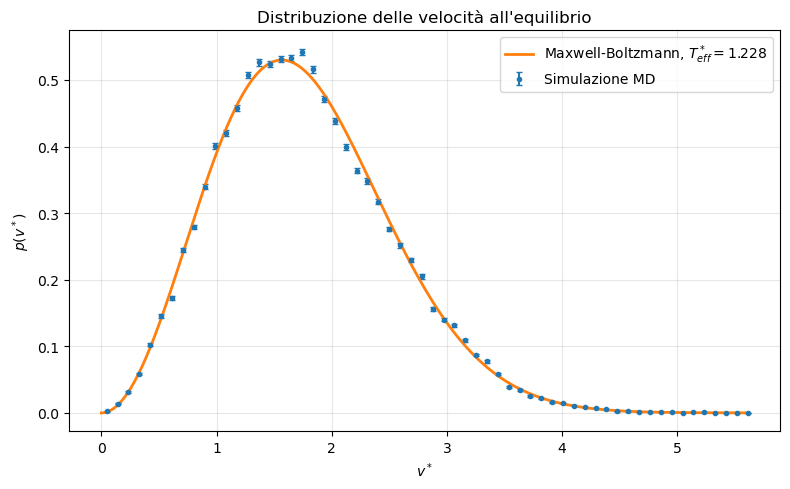

In [69]:
def maxwell_boltzmann(v, T):
    return (
        4.0 * np.pi * v**2
        / (2.0 * np.pi * T)**1.5
        * np.exp(-v**2 / (2.0 * T))
    )


# Curva teorica continua
v_theory = np.linspace(
    0.0,
    v_eq.max(),
    500
)

p_theory = maxwell_boltzmann(
    v_theory,
    T_eff
)


plt.figure(figsize=(8, 5))

plt.errorbar(
    v_eq,
    p_eq,
    yerr=p_eq_err,
    fmt="o",
    markersize=3,
    capsize=2,
    label="Simulazione MD"
)

plt.plot(
    v_theory,
    p_theory,
    linewidth=2,
    label=rf"Maxwell-Boltzmann, $T_{{eff}}^*={T_eff:.3f}$"
)

plt.xlabel(r"$v^*$")
plt.ylabel(r"$p(v^*)$")
plt.title("Distribuzione delle velocità all'equilibrio")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

Come si nota dal grafico, la simulazione numerica risulta compatibile con la distribuzione di Maxwell-Boltzmann.

## Evoluzione della configurazione spaziale

La condizione iniziale è caratterizzata anche da un forte ordine spaziale.

Le particelle sono inizialmente disposte su un reticolo FCC confinato in una regione di lato pari a metà della scatola lungo ciascuna direzione. Il volume inizialmente occupato è quindi

$$
V_{\mathrm{iniziale}}
=
\frac{V}{8}.
$$

Durante l'evoluzione le particelle si allontanano dalla struttura cristallina iniziale e tendono a occupare in modo più uniforme il volume disponibile.

Il passaggio da una configurazione molto ordinata e localizzata a una configurazione spazialmente più omogenea può essere interpretato come un'evoluzione verso macrostati caratterizzati da un numero molto maggiore di configurazioni microscopiche compatibili e quindi da una maggiore entropia.

In [71]:
# Cartella contenente le configurazioni salvate
config_dir = output_dir / "CONFIG"

# Snapshot scelti per mostrare l'espansione
snapshot_steps = [0, 100, 200, 300, 500, 1000, 5000, 20000, 50000, 100000]

# Corrispondenti tempi ridotti
snapshot_times = [
    step * delta_t
    for step in snapshot_steps
]


def read_xyz(filename):
    # Le prime due righe contengono numero di particelle e commento
    data = np.loadtxt(
        filename,
        skiprows=2,
        usecols=(1, 2, 3)
    )
    
    return data


configs = {}

for step, t in zip(snapshot_steps, snapshot_times):
    
    filename = config_dir / f"config_{step}.xyz"
    
    configs[t] = read_xyz(filename)

print("Configurazioni caricate:")
for t in configs:
    print(f"t* = {t}")

Configurazioni caricate:
t* = 0.0
t* = 0.1
t* = 0.2
t* = 0.3
t* = 0.5
t* = 1.0
t* = 5.0
t* = 20.0
t* = 50.0
t* = 100.0


L* = 17.235


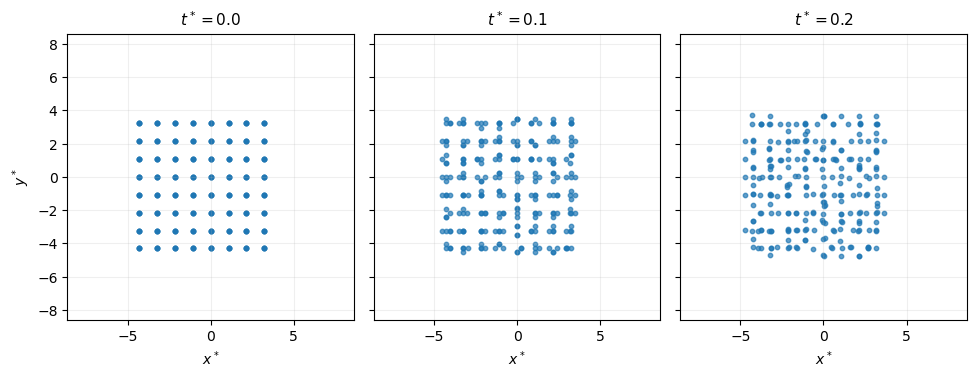

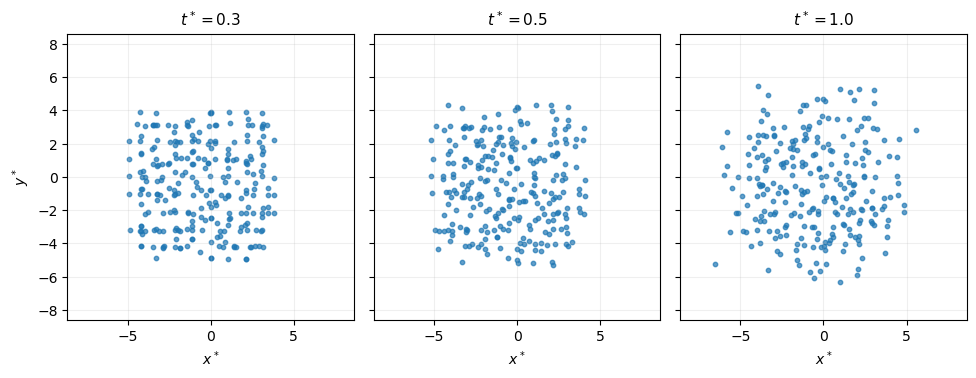

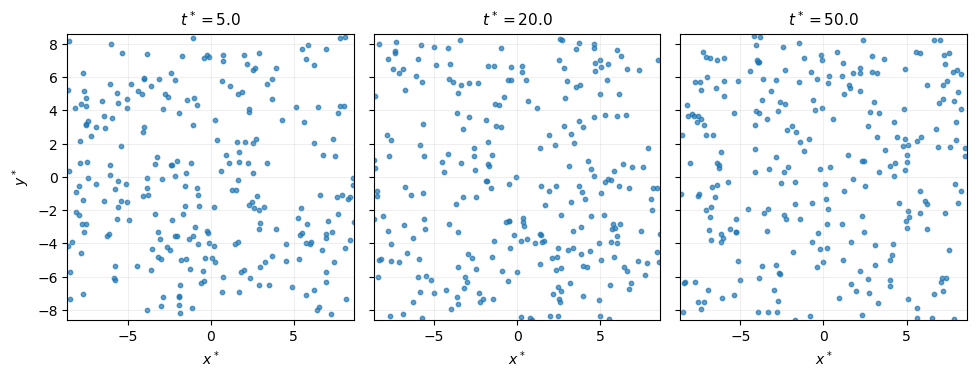

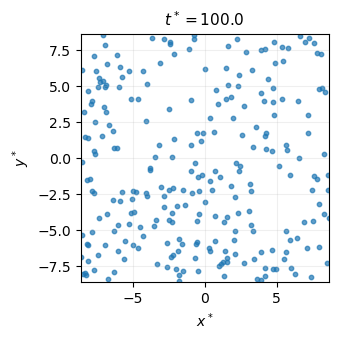

In [74]:
# Lato della scatola
N = 256
rho = 0.05

L = (N / rho)**(1/3)

print(f"L* = {L:.3f}")

# Trasforma il dizionario in lista per poterlo dividere in gruppi
config_items = list(configs.items())

# Numero di grafici per riga
group_size = 3

for start in range(0, len(config_items), group_size):

    group = config_items[start:start + group_size]

    fig, axes = plt.subplots(
        1,
        len(group),
        figsize=(10, 3.5),
        sharex=True,
        sharey=True
    )

    # Se nel gruppo finale resta una sola configurazione
    if len(group) == 1:
        axes = [axes]

    for ax, (t, config) in zip(axes, group):

        x = config[:, 0]
        y = config[:, 1]

        ax.scatter(
            x,
            y,
            s=10,
            alpha=0.7
        )

        ax.set_xlim(-L/2, L/2)
        ax.set_ylim(-L/2, L/2)

        ax.set_title(
            rf"$t^*={t:.1f}$",
            fontsize=11
        )

        ax.set_xlabel(r"$x^*$")
        ax.set_aspect("equal")
        ax.grid(alpha=0.2)

    axes[0].set_ylabel(r"$y^*$")

    plt.tight_layout()
    plt.show()

### Evoluzione della configurazione spaziale

La sequenza delle configurazioni mostra chiaramente la rapida perdita dell'ordine spaziale iniziale.

A $t^*=0$ le particelle occupano solamente la regione centrale della scatola e presentano la struttura regolare del reticolo FCC. La configurazione iniziale è quindi fortemente ordinata e occupa solo una frazione del volume disponibile.

Già a $t^*=0.1$ sono visibili gli effetti della dinamica: le particelle iniziano ad allontanarsi dalle posizioni reticolari e la struttura FCC comincia a deformarsi. A $t^*=0.2$ e $t^*=0.3$ l'ordine iniziale risulta progressivamente meno riconoscibile e il sistema inizia contemporaneamente a espandersi nello spazio disponibile.

Per tempi maggiori la struttura cristallina iniziale viene completamente persa. Le particelle continuano a diffondersi nella scatola fino a produrre una configurazione macroscopicamente più omogenea.

Questa evoluzione spaziale avviene contemporaneamente al rilassamento della distribuzione delle velocità osservato in precedenza:

$$
p_0(v^*)=\delta(v^*-\sqrt{6})
\quad\longrightarrow\quad
p_{\mathrm{MB}}(v^*,T_{\mathrm{eff}}^*).
$$

Il sistema perde quindi memoria sia dell'ordine iniziale delle posizioni sia della particolare distribuzione iniziale delle velocità.

## Interpretazione in termini di entropia

La configurazione iniziale rappresenta un macrostato estremamente particolare: le particelle sono localizzate in una piccola regione della scatola, le loro posizioni sono fortemente ordinate e tutti i moduli delle velocità sono inizialmente uguali.

In termini statistici, l'entropia di Boltzmann è legata al numero $\Omega$ di microstati compatibili con un determinato macrostato,

$$
S=k_B\ln\Omega.
$$

Uno stato macroscopicamente omogeneo, nel quale le particelle possono occupare l'intera scatola e possiedono una distribuzione di velocità di Maxwell-Boltzmann, è compatibile con un numero enormemente maggiore di microstati rispetto alla configurazione iniziale.

L'evoluzione osservata può quindi essere interpretata come un passaggio spontaneo da uno stato macroscopico molto particolare e a bassa entropia verso uno stato molto più probabile e caratterizzato da una maggiore entropia.

È importante sottolineare che l'aumento di entropia è una descrizione statistica dell'evoluzione macroscopica. Le equazioni microscopiche utilizzate nella Molecular Dynamics rimangono infatti reversibili nel tempo. Questo aspetto verrà analizzato direttamente nell'Esercizio 04.3.

## Medie progressive delle grandezze termodinamiche

Le grandezze termodinamiche misurate nei singoli blocchi presentano inevitabilmente delle fluttuazioni.

Per verificarne la stabilizzazione statistica vengono quindi considerate anche le medie progressive ottenute mediante data blocking.

Per una generica osservabile $A$, dopo $n$ blocchi viene calcolata la media progressiva

$$
\langle A\rangle_n
=
\frac{1}{n}
\sum_{i=1}^{n} A_i,
$$

insieme alla relativa incertezza statistica.

Poiché la prima parte della simulazione corrisponde al transiente di equilibrazione, le medie progressive calcolate sull'intera traiettoria mantengono inizialmente memoria dello stato fortemente fuori equilibrio. A tempi sufficientemente lunghi, tuttavia, il contributo del transiente diventa progressivamente meno rilevante.

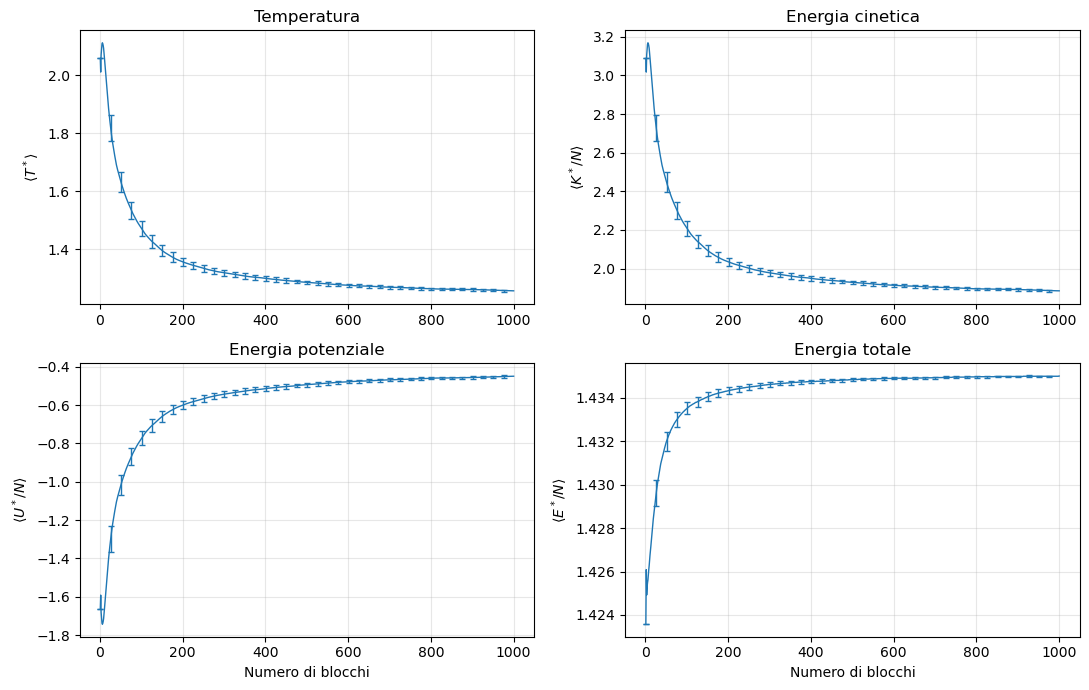

In [76]:
# Medie progressive e relative incertezze

error_every = 25

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 7)
)

# Temperatura
axes[0, 0].errorbar(
    temperature[:, 0],
    temperature[:, 2],
    yerr=temperature[:, 3],
    fmt="-",
    linewidth=1,
    capsize=2,
    errorevery=error_every
)

axes[0, 0].set_title("Temperatura")
axes[0, 0].set_ylabel(r"$\langle T^* \rangle$")
axes[0, 0].grid(alpha=0.3)


# Energia cinetica
axes[0, 1].errorbar(
    kinetic_energy[:, 0],
    kinetic_energy[:, 2],
    yerr=kinetic_energy[:, 3],
    fmt="-",
    linewidth=1,
    capsize=2,
    errorevery=error_every
)

axes[0, 1].set_title("Energia cinetica")
axes[0, 1].set_ylabel(r"$\langle K^*/N \rangle$")
axes[0, 1].grid(alpha=0.3)


# Energia potenziale
axes[1, 0].errorbar(
    potential_energy[:, 0],
    potential_energy[:, 2],
    yerr=potential_energy[:, 3],
    fmt="-",
    linewidth=1,
    capsize=2,
    errorevery=error_every
)

axes[1, 0].set_title("Energia potenziale")
axes[1, 0].set_ylabel(r"$\langle U^*/N \rangle$")
axes[1, 0].set_xlabel("Numero di blocchi")
axes[1, 0].grid(alpha=0.3)


# Energia totale
axes[1, 1].errorbar(
    total_energy[:, 0],
    total_energy[:, 2],
    yerr=total_energy[:, 3],
    fmt="-",
    linewidth=1,
    capsize=2,
    errorevery=error_every
)

axes[1, 1].set_title("Energia totale")
axes[1, 1].set_ylabel(r"$\langle E^*/N \rangle$")
axes[1, 1].set_xlabel("Numero di blocchi")
axes[1, 1].grid(alpha=0.3)


plt.tight_layout()
plt.show()

Le medie progressive mostrano gli effetti del forte transiente iniziale sulle grandezze termodinamiche.

La temperatura e le componenti cinetica e potenziale dell'energia cambiano significativamente durante la fase iniziale, poiché il sistema redistribuisce l'energia mentre evolve dalla configurazione ordinata verso lo stato di equilibrio.

L'energia totale presenta invece variazioni molto più piccole, come previsto per una simulazione microcanonica $NVE$.

La conservazione di

$$
E^*=K^*+U^*
$$

costituisce quindi anche un controllo della stabilità numerica dell'integrazione Molecular Dynamics.

# Esercizio 04.3 — Reversibilità temporale della Molecular Dynamics

In questo esercizio viene studiata numericamente la reversibilità temporale della dinamica molecolare.

Si parte dalla stessa configurazione iniziale a bassa entropia utilizzata nell'Esercizio 04.2 e si lascia evolvere il sistema per un certo numero di passi mediante l'algoritmo di Verlet.

Raggiunto un tempo prefissato, la direzione temporale viene invertita e il sistema viene fatto evolvere nuovamente per lo stesso numero di passi.

Vengono considerate due diverse durate della traiettoria forward:

$$
N_{\mathrm{forward}}=5\times10^3
$$

e

$$
N_{\mathrm{forward}}=5\times10^4.
$$

Con il passo temporale

$$
\Delta t^*=0.001,
$$

queste corrispondono rispettivamente ai tempi ridotti

$$
t_{\mathrm{rev}}^*=5
$$

e

$$
t_{\mathrm{rev}}^*=50.
$$

L'algoritmo di Verlet utilizza sia la posizione corrente $\mathbf r_n$ sia quella precedente $\mathbf r_{n-1}$. L'inversione temporale viene quindi implementata in modo coerente con lo stato numerico dell'integratore, in modo che la successiva evoluzione tenti di ripercorrere la traiettoria precedente in direzione opposta.

L'obiettivo è confrontare, nelle due direzioni temporali:

- la temperatura media di ogni blocco;
- l'energia potenziale media per particella;
- la configurazione spaziale finale con quella iniziale.

Il confronto permette di verificare fino a quale scala temporale la traiettoria numerica riesca a essere effettivamente ricostruita.

Per rendere immediato il confronto tra le due evoluzioni, le traiettorie forward e backward verrà rappresentate sullo stesso asse temporale.

La traiettoria forward viene mostrata nel verso usuale, a partire da $t^*=0$ fino all'istante di inversione $t_{\mathrm{rev}}^*$.

La traiettoria backward parte invece dallo stato finale della traiettoria forward, cioè da $t^*=t_{\mathrm{rev}}^*$, e viene rappresentata con il tempo che decresce verso $t^*=0$.

Di conseguenza, nei grafici che verranno mostrati, il punto più a destra rappresenta l'istante in cui viene effettuata l'inversione temporale, mentre spostarsi verso sinistra lungo la curva backward corrisponde ad aumentare il tempo trascorso dopo l'inversione.

Se la traiettoria fosse ricostruita perfettamente, le curve forward e backward risulterebbero quindi sovrapposte sull'intero intervallo.

## Caso $5\times10^3$ step

Nel primo esperimento il sistema evolve per

$$
5000
$$

passi in avanti e successivamente per altri

$$
5000
$$

passi dopo l'inversione temporale.

Vengono utilizzati blocchi da $100$ step, ciascuno corrispondente a

$$
\Delta t_{\mathrm{block}}^*
=
100\cdot0.001
=
0.1.
$$

La traiettoria forward è quindi costituita da $50$ blocchi e raggiunge

$$
t_{\mathrm{rev}}^*=5.
$$

I successivi $50$ blocchi descrivono invece la traiettoria di ritorno.

Poiché le grandezze riportate nei file sono medie di blocco, a ogni blocco viene associato il tempo centrale dell'intervallo temporale corrispondente. In questo modo le grandezze forward e backward possono essere confrontate direttamente allo stesso valore di $t^*$.

In [108]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Cartella con gli output del caso da 5000 step
output_dir = Path("Esercizio_04.3/NSL_SIMULATOR/OUTPUT")

temperature = np.loadtxt(
    output_dir / "temperature_50.dat"
)

potential_energy = np.loadtxt(
    output_dir / "potential_energy_50.dat"
)

# Parametri temporali
delta_t = 0.001
nsteps_per_block = 100

delta_t_block = (
    nsteps_per_block * delta_t
)

# Metà dei blocchi appartiene alla traiettoria forward
n_forward = len(temperature) // 2

print("Blocchi forward :", n_forward)
print("Blocchi backward:", len(temperature) - n_forward)
print(
    "Tempo di inversione t* =",
    n_forward * delta_t_block
)

Blocchi forward : 50
Blocchi backward: 50
Tempo di inversione t* = 5.0


In [109]:
# Temperatura media di ciascun blocco
T_forward = temperature[:n_forward, 1]
T_backward = temperature[n_forward:, 1]

# Energia potenziale media di ciascun blocco
U_forward = potential_energy[:n_forward, 1]
U_backward = potential_energy[n_forward:, 1]

# Tempi centrali dei blocchi forward
t_forward = (
    np.arange(n_forward) + 0.5
) * delta_t_block

# La traiettoria backward viene rappresentata
# nella direzione temporale opposta
t_backward = (
    n_forward
    - np.arange(n_forward)
    - 0.5
) * delta_t_block

## Confronto tra evoluzione forward e backward

Se la dinamica numerica fosse perfettamente reversibile, dopo l'inversione temporale il sistema dovrebbe ripercorrere esattamente la traiettoria precedente.

Una grandezza dipendente solamente dallo stato microscopico, come la temperatura cinetica o l'energia potenziale, dovrebbe quindi assumere durante il ritorno gli stessi valori osservati durante l'evoluzione forward, ma in ordine temporale inverso.

Il confronto diretto tra le due traiettorie permette di quantificare la qualità della reversibilità numerica.

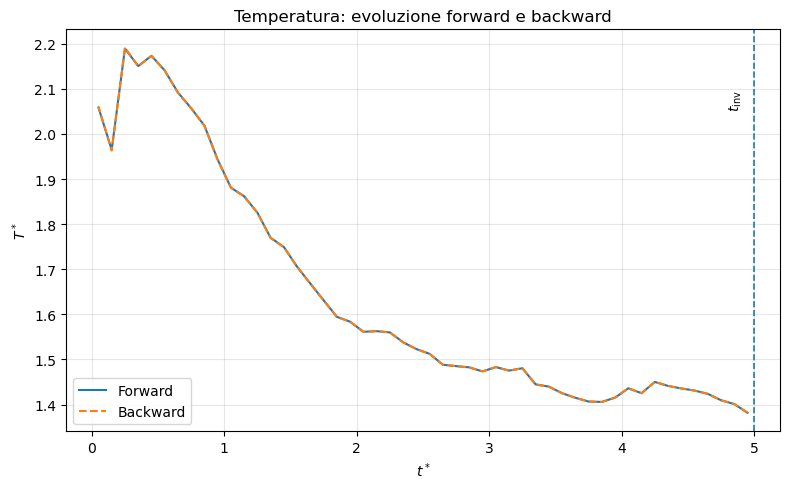

In [113]:
t_inv = 5
plt.figure(figsize=(8, 5))

plt.plot(
    t_forward,
    T_forward,
    linewidth=1.5,
    label="Forward"
)

plt.plot(
    t_backward,
    T_backward,
    linewidth=1.5,
    linestyle="--",
    label="Backward"
)



plt.xlabel(r"$t^*$")
plt.ylabel(r"$T^*$")
plt.axvline(
    t_inv,
    linestyle="--",
    linewidth=1.2
)
plt.title(
    "Temperatura: evoluzione forward e backward"
)
plt.text(
    t_inv - 0.2,
    plt.ylim()[0] + 0.85*(plt.ylim()[1] - plt.ylim()[0]),
    r"$t_{\mathrm{inv}}$",
    rotation=90,
    va="top"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

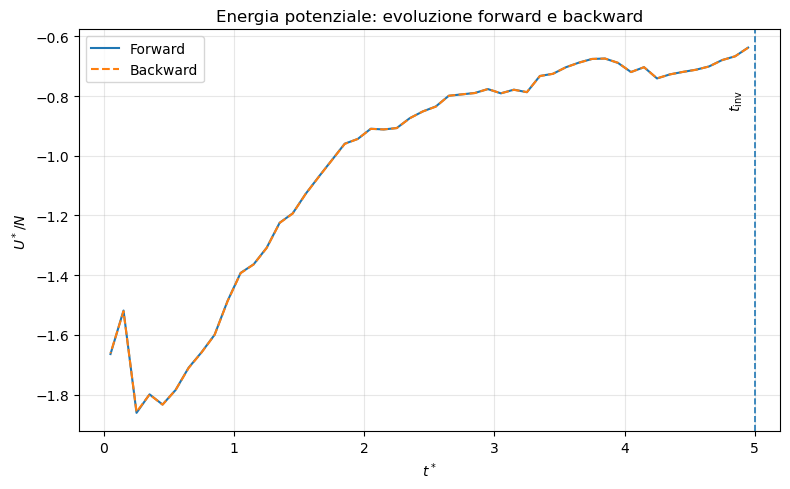

In [114]:

plt.figure(figsize=(8, 5))

plt.plot(
    t_forward,
    U_forward,
    linewidth=1.5,
    label="Forward"
)

plt.plot(
    t_backward,
    U_backward,
    linewidth=1.5,
    linestyle="--",
    label="Backward"
)



plt.xlabel(r"$t^*$")
plt.ylabel(r"$U^*/N$")

plt.title(
    "Energia potenziale: evoluzione forward e backward"
)
plt.axvline(
    t_inv,
    linestyle="--",
    linewidth=1.2
)
plt.text(
    t_inv - 0.2,
    plt.ylim()[0] + 0.85*(plt.ylim()[1] - plt.ylim()[0]),
    r"$t_{\mathrm{inv}}$",
    rotation=90,
    va="top"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### Reversibilità per $5\times10^3$ step

Nel caso in cui l'inversione temporale venga effettuata dopo

$$
5\times10^3
$$

passi di Molecular Dynamics, corrispondenti a

$$
t_{\mathrm{rev}}^*=5,
$$

le curve ottenute durante l'evoluzione forward e backward risultano quasi perfettamente sovrapposte.

Questo comportamento si osserva sia per la temperatura media di blocco sia per l'energia potenziale media per particella.

Il risultato indica che, su questa scala temporale, l'inversione dello stato numerico è sufficientemente accurata da permettere al sistema di ripercorrere quasi esattamente la traiettoria precedente.

In particolare, il sistema segue la sequenza

$$
\text{stato iniziale}
\longrightarrow
\text{stato a } t^*=5
\longrightarrow
\text{stato iniziale},
$$

con differenze molto piccole dovute alla precisione numerica finita e alla discretizzazione temporale.

In [115]:
# Confronto quantitativo forward-backward

# Per confrontare gli stessi tempi, la traiettoria backward
# viene letta in ordine inverso
T_backward_reverse = T_backward[::-1]
U_backward_reverse = U_backward[::-1]

delta_T = T_backward_reverse - T_forward
delta_U = U_backward_reverse - U_forward

print("Temperatura")
print(
    "Differenza media assoluta =",
    np.mean(np.abs(delta_T))
)
print(
    "Differenza massima assoluta =",
    np.max(np.abs(delta_T))
)

print()

print("Energia potenziale")
print(
    "Differenza media assoluta =",
    np.mean(np.abs(delta_U))
)
print(
    "Differenza massima assoluta =",
    np.max(np.abs(delta_U))
)

Temperatura
Differenza media assoluta = 0.0003335999999999828
Differenza massima assoluta = 0.0021199999999996777

Energia potenziale
Differenza media assoluta = 0.0005031599999999936
Differenza massima assoluta = 0.0031799999999999606


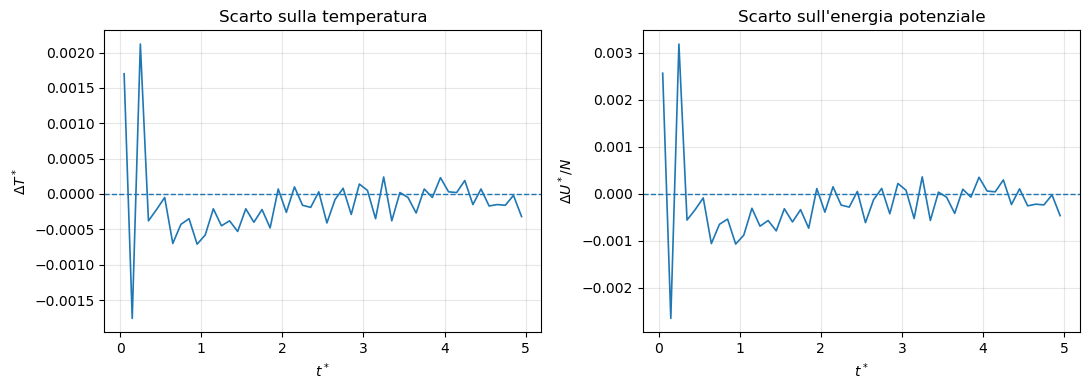

In [116]:

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4)
)

axes[0].plot(
    t_forward,
    delta_T,
    linewidth=1.2
)

axes[0].axhline(
    0.0,
    linestyle="--",
    linewidth=1
)

axes[0].set_xlabel(r"$t^*$")
axes[0].set_ylabel(r"$\Delta T^*$")
axes[0].set_title("Scarto sulla temperatura")
axes[0].grid(alpha=0.3)


axes[1].plot(
    t_forward,
    delta_U,
    linewidth=1.2
)

axes[1].axhline(
    0.0,
    linestyle="--",
    linewidth=1
)

axes[1].set_xlabel(r"$t^*$")
axes[1].set_ylabel(r"$\Delta U^*/N$")
axes[1].set_title("Scarto sull'energia potenziale")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Caso $5\times10^4$ step

Nel secondo esperimento l'inversione temporale viene effettuata dopo

$$
N_{\mathrm{forward}}=5\times10^4
$$

passi di Molecular Dynamics.

Con

$$
\Delta t^*=0.001,
$$

il tempo di inversione è

$$
t_{\mathrm{rev}}^*
=
5\times10^4\cdot0.001
=
50.
$$

Utilizzando ancora blocchi da $100$ step, la traiettoria forward è costituita da $500$ blocchi e la successiva traiettoria backward da altri $500$ blocchi.

Il confronto con il caso da $5\times10^3$ step permette di verificare se la reversibilità numerica viene mantenuta anche su una traiettoria dieci volte più lunga.

In [117]:
# Cartella con gli output del caso da 5000 step
output_dir = Path("Esercizio_04.3/NSL_SIMULATOR/OUTPUT")

temperature = np.loadtxt(
    output_dir / "temperature_500.dat"
)

potential_energy = np.loadtxt(
    output_dir / "potential_energy_500.dat"
)

# Parametri temporali
delta_t = 0.001
nsteps_per_block = 100

delta_t_block = (
    nsteps_per_block * delta_t
)

# Metà dei blocchi appartiene alla traiettoria forward
n_forward = len(temperature) // 2

print("Blocchi forward :", n_forward)
print("Blocchi backward:", len(temperature) - n_forward)
print(
    "Tempo di inversione t* =",
    n_forward * delta_t_block
)

Blocchi forward : 500
Blocchi backward: 500
Tempo di inversione t* = 50.0


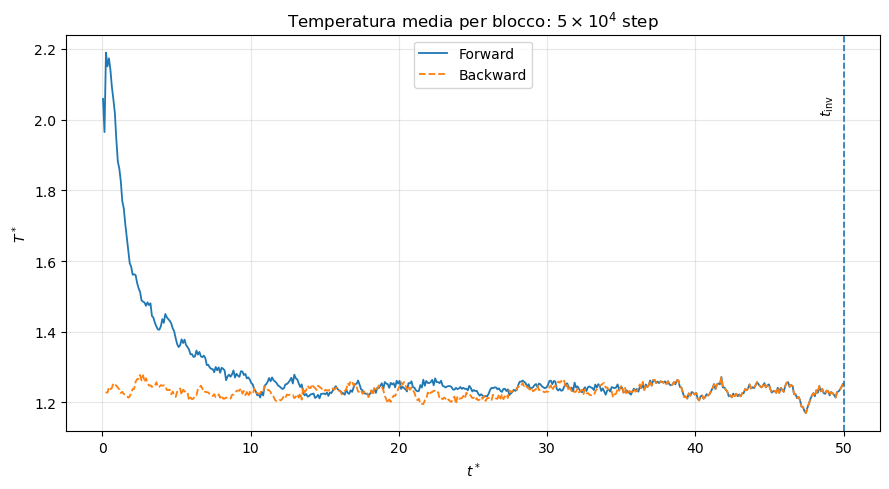

In [122]:
# Temperatura media di ciascun blocco
T_forward = temperature[:n_forward, 1]
T_backward = temperature[n_forward:, 1]

# Energia potenziale media di ciascun blocco
U_forward = potential_energy[:n_forward, 1]
U_backward = potential_energy[n_forward:, 1]

# Tempi centrali dei blocchi forward
t_forward = (
    np.arange(n_forward) + 0.5
) * delta_t_block

# La traiettoria backward viene rappresentata
# nella direzione temporale opposta
t_backward = (
    n_forward
    - np.arange(n_forward)
    - 0.5
) * delta_t_block

t_inv = 50

plt.figure(figsize=(9, 5))

plt.plot(
    t_forward,
    T_forward,
    linewidth=1.3,
    label="Forward"
)

plt.plot(
    t_backward,
    T_backward,
    linewidth=1.3,
    linestyle="--",
    label="Backward"
)

plt.xlabel(r"$t^*$")
plt.ylabel(r"$T^*$")
plt.axvline(
    t_inv,
    linestyle="--",
    linewidth=1.2
)

plt.text(
    t_inv - 1.6,
    plt.ylim()[0] + 0.85*(plt.ylim()[1] - plt.ylim()[0]),
    r"$t_{\mathrm{inv}}$",
    rotation=90,
    va="top"
)

plt.title(
    r"Temperatura media per blocco: $5\times10^4$ step"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()



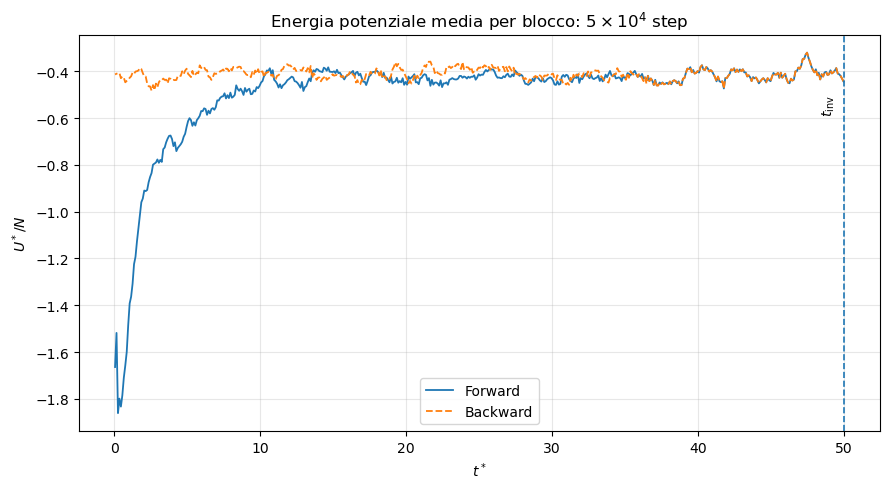

In [124]:
plt.figure(figsize=(9, 5))

plt.plot(
    t_forward,
    U_forward,
    linewidth=1.3,
    label="Forward"
)

plt.plot(
    t_backward,
    U_backward,
    linewidth=1.3,
    linestyle="--",
    label="Backward"
)
plt.axvline(
    t_inv,
    linestyle="--",
    linewidth=1.2
)
plt.xlabel(r"$t^*$")
plt.ylabel(r"$U^*/N$")
plt.text(
    t_inv - 1.6,
    plt.ylim()[0] + 0.85*(plt.ylim()[1] - plt.ylim()[0]),
    r"$t_{\mathrm{inv}}$",
    rotation=90,
    va="top"
)
plt.title(
    r"Energia potenziale media per blocco: $5\times10^4$ step"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

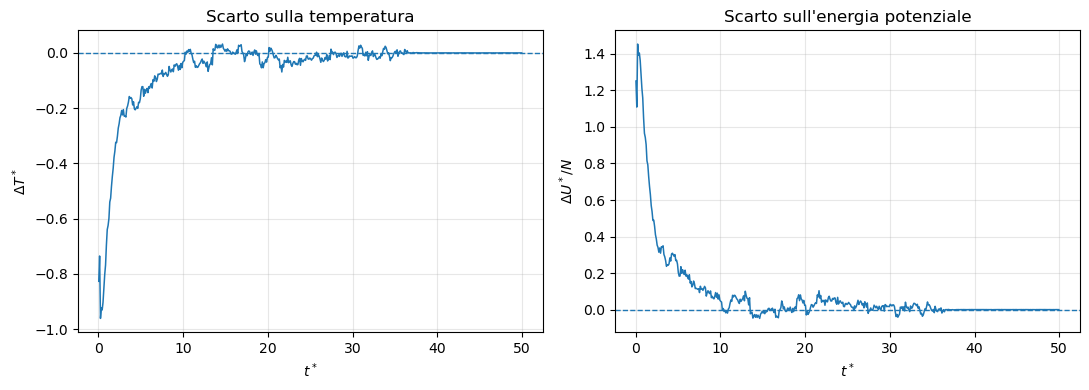

In [125]:
T_backward_reverse_50000 = T_backward[::-1]
U_backward_reverse_50000 = U_backward[::-1]

delta_T_50000 = (
    T_backward_reverse_50000
    - T_forward
)

delta_U_50000 = (
    U_backward_reverse_50000
    - U_forward
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4)
)

axes[0].plot(
    t_forward,
    delta_T_50000,
    linewidth=1.1
)

axes[0].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[0].set_xlabel(r"$t^*$")
axes[0].set_ylabel(r"$\Delta T^*$")
axes[0].set_title("Scarto sulla temperatura")
axes[0].grid(alpha=0.3)


axes[1].plot(
    t_forward,
    delta_U_50000,
    linewidth=1.1
)

axes[1].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[1].set_xlabel(r"$t^*$")
axes[1].set_ylabel(r"$\Delta U^*/N$")
axes[1].set_title("Scarto sull'energia potenziale")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Discussione dei risultati e conclusioni

Il confronto tra le simulazioni con $5\times10^3$ e $5\times10^4$ step mostra chiaramente il ruolo della stabilità numerica nella reversibilità della Molecular Dynamics.

Nel caso più breve, con inversione temporale a

$$
t_{\mathrm{rev}}^*=5,
$$

la traiettoria backward riproduce quasi perfettamente quella forward. La temperatura e l'energia potenziale medie per blocco risultano praticamente sovrapposte e gli scarti rimangono molto piccoli.

Il comportamento cambia sensibilmente quando l'inversione viene effettuata dopo

$$
t_{\mathrm{rev}}^*=50.
$$

È importante osservare che, nei grafici degli scarti, il punto $t^*=50$ rappresenta l'istante in cui viene effettuata l'inversione temporale.

In prossimità di questo punto gli scarti sono praticamente nulli, poiché la traiettoria backward parte esattamente dallo stato finale raggiunto dalla traiettoria forward.

Procedendo invece verso valori più piccoli di $t^*$ nel grafico significa allontanarsi progressivamente dall'istante di inversione lungo la traiettoria backward. Gli errori numerici hanno quindi sempre più tempo per essere amplificati e le due traiettorie iniziano gradualmente a divergere.

Gli scarti

$$
\Delta T^*
=
T^*_{\mathrm{backward}}
-
T^*_{\mathrm{forward}}
$$

e

$$
\Delta U^*
=
\frac{U^*_{\mathrm{backward}}}{N}
-
\frac{U^*_{\mathrm{forward}}}{N}
$$

crescono infatti man mano che ci si sposta da $t^*=50$ verso $t^*=0$.

Vicino a $t^*=0$ la differenza diventa molto grande: la traiettoria backward non riesce più a ricostruire il forte transiente caratteristico della configurazione iniziale a bassa entropia.

In particolare, mentre nella traiettoria forward la temperatura parte da un valore vicino a $T^*=2$ e l'energia potenziale presenta valori molto più negativi, nella traiettoria backward entrambe le grandezze rimangono vicine ai valori caratteristici dello stato equilibrato.

Il sistema non riesce quindi più a ritornare alla particolare configurazione macroscopica iniziale.

Questo risultato non implica una violazione della reversibilità delle equazioni microscopiche. Le equazioni di Newton e l'algoritmo di Verlet sono reversibili in linea di principio. Tuttavia, durante una simulazione numerica sono inevitabilmente presenti piccoli errori dovuti alla discretizzazione temporale e alla precisione finita del calcolo.

La dinamica molecolare è inoltre caotica: perturbazioni inizialmente estremamente piccole possono essere progressivamente amplificate durante l'evoluzione. Dopo una traiettoria sufficientemente lunga, gli errori numerici accumulati impediscono quindi di ricostruire esattamente lo stato microscopico necessario per percorrere all'indietro la traiettoria originale. I risultati ottenuti sono l'evidenza della cosiddetta **instabilità di Lyapunov**.

Il confronto tra i due casi evidenzia quindi che

$$
5\times10^3\ \text{step}
\quad\Rightarrow\quad
\text{reversibilità numerica quasi completa},
$$

mentre

$$
5\times10^4\ \text{step}
\quad\Rightarrow\quad
\text{progressiva perdita della traiettoria microscopica}.
$$

L'esperimento mostra così come una dinamica microscopicamente reversibile possa risultare, su tempi sufficientemente lunghi, praticamente irreversibile dal punto di vista numerico e macroscopico.